# Compare with Hiroshi's trajectories

*19 May 2025*

As a sanity check, want to compare trajectories computer by SeaIcBacktrack and those calculated for Sumata et al 2022.

Comparing one single trajectory by Hiroshi. Just a sanity check, not meant as a rigourous anything. The match shoudl be near 100%, if it is I will go ahead and trust that we can rely on the `SeaIceBackTrack` trajectories. 

*Note*: Did the comparison *almost correct* - an index error (`lat0, lon0=lat[1], lat[0]` instead of `lat0, lon0=lat[0], lat[0]`) made a small difference in the starting point.

**Verdict** is that these trajectories are basically identical and follow each other closely over years. 

**-> SeaIceBackTracj seems to do a good job!** More or less identical, the tiny difference is probably the initial starting point. Concluding that the exact interpolation method doesn't matter much.

Can probably say that we have compared with Hiroshi et al and they are identical to within X km after Y months. Or somethign to that effect. The island skipping stuff will need its own explanations though.

In [1]:
#Imports 
import pickle
import datetime

import pandas as pd
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean
from kval.maps import quickmap

%matplotlib widget

## Read Hiroshi's trajectory

In [2]:
# Location of the files
ddir_hiroshi = '../files_from_hiroshi/'

In [3]:
# Load HS's python script which defines his particle class
%run '../files_from_hiroshi/trajectory_util.py'

/home/oyvindl/work/code/python/SeaIceBacktrack/validation/trajectory_vs_sumata_new/files_from_hiroshi/trajectory_util.py:403: SyntaxWarning: invalid escape sequence '\ '
  sys.exit('ERROR: data does not exit, \    fname =' + fname)


#### Select one of the HS trajectories 

In [4]:
# Load one of the trajectory files
with open(f'{ddir_hiroshi}/FS.2018.01.backward_traj.731_days.n_8.pkl', 'rb') as f:
    trajectories = pickle.load(f) 

In [5]:
# Choose an index
traj_ind = 0

# Select the trajectory
traj_sel = trajectories[traj_ind]

# Extract lon/lat
lon_traj = np.array(traj_sel.lonlats)[:, 0]
lat_traj = np.array(traj_sel.lonlats)[:, 1]
time_traj = traj_sel.stamps

# Extract start date and coordinate
start_date_traj = time_traj[0]
lon0_traj = lon_traj[0]
lat0_traj = lat_traj[0]

## Backtrack using SeaIceBackTrack

In [6]:
# Ignore non-useful warnings
import warnings
warnings.simplefilter("ignore")

#### Run the notebooks for setting up the class and preparing the input data

In [7]:
print('Running other notebooks: Preparing data..\r', end = '')
%run "Load and prepare data.ipynb"
print('Running other notebooks: Defining particle tracking class..', end = '')
%run "Define particle tracking class.ipynb"
print('  ..done.')

Running other notebooks: Defining particle tracking class..  ..done.


##### Choose whether to compute or load from previously saved file

In [8]:
compute_traj = True # Either load or recompute (takes 30-60 minutes)

##### *If selected*: Load from file

In [9]:
if not compute_traj:
    with open('trajectory_saved.p', 'wb') as f:
        pickle.dump(P, f)

##### *Otherwise*: Compute trajectories 

Note: Trajectory goes through the TPD and into the Beaufort gyre over >3 years and therefore takes a long time to compute (several hours). This is not the speediest piece of code..

In [10]:
if compute_traj:
    IC_dict = {'D':D, 
          'lat0':lat0_traj, 
          'lon0':lon0_traj, 
          'time0':start_date_traj, 
          'MASK':MASK, 'interp_method':'linear', 'end_criteria':'ABC' }
    
    # Set up object, compute the trajectory, and save to TRAJS
    P = ice_particle(IC_dict)
    P.backtrack()

Setting up object ..
 ..done.
HIT OPEN WATER! () step 1214 (19 Sep 2014) - 2717.3 km ..


### Plot the trajectories together

Note: If loaded from the file there may have been a (small) error in start latitude. (Fixed in the code above but didn't bother to rerun the trajectory)

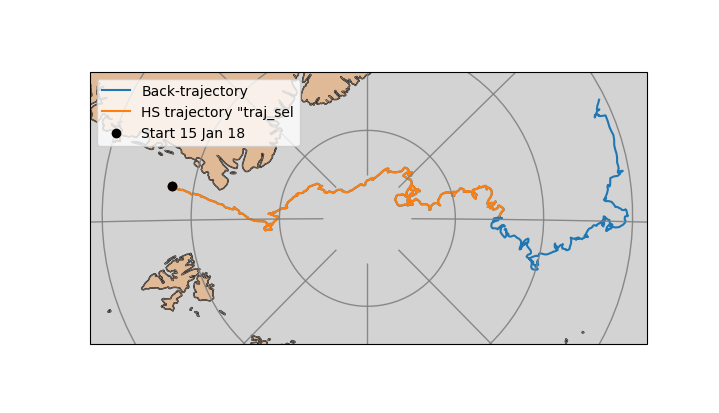

In [12]:
plt.close('all')

crs = ccrs.Stereographic(central_latitude=80.0, central_longitude=90.0, false_easting=0.0, 
                          false_northing=0.0, true_scale_latitude=None, globe=None)
fig = plt.figure(figsize = [7.19, 4.14])
ax = fig.add_subplot(111, projection=crs)

ax.coastlines()
ax.add_feature(cfeature.LAND, color = 'tab:orange', alpha = 0.3)
ax.add_feature(cfeature.COASTLINE, color = 'gray', lw = 0.5)
ax.set_extent([-45, 125, 60, 60])

ax.set_xlim(-1776630, 1790654)
ax.set_ylim(315596, 2059603)
ax.set_facecolor('lightgray')

ax.plot(lon0_traj, lat0_traj, 'or',transform = ccrs.PlateCarree(), )


Plat, Plon = P.ease2_to_latlon.transform(P.x, P.y)
# Massage to make lon continuous
Plon[Plon<100] +=360

datestr = num2date(date2num(P.time0)).strftime('%d %b %y')

ax.plot(Plon, Plat, transform = ccrs.PlateCarree(), label = 'Back-trajectory')
ax.plot(lon_traj, lat_traj, transform = ccrs.PlateCarree(), label = 'HS trajectory "traj_sel')
ax.plot(Plon[0], Plat[0], 'ok', transform = ccrs.PlateCarree(), label = 'Start %s'%datestr)

gls = ax.gridlines(draw_labels=False, crs=ccrs.PlateCarree(), lw=1, color="gray",
        y_inline=True, xlocs=range(-180,180,45), ylocs=range(0,90,5), alpha = 0.9,  ylim=87.5, )
ax.legend()

## PLot lon/lat on time together

In [15]:
Pdate = num2date(P.time_num)

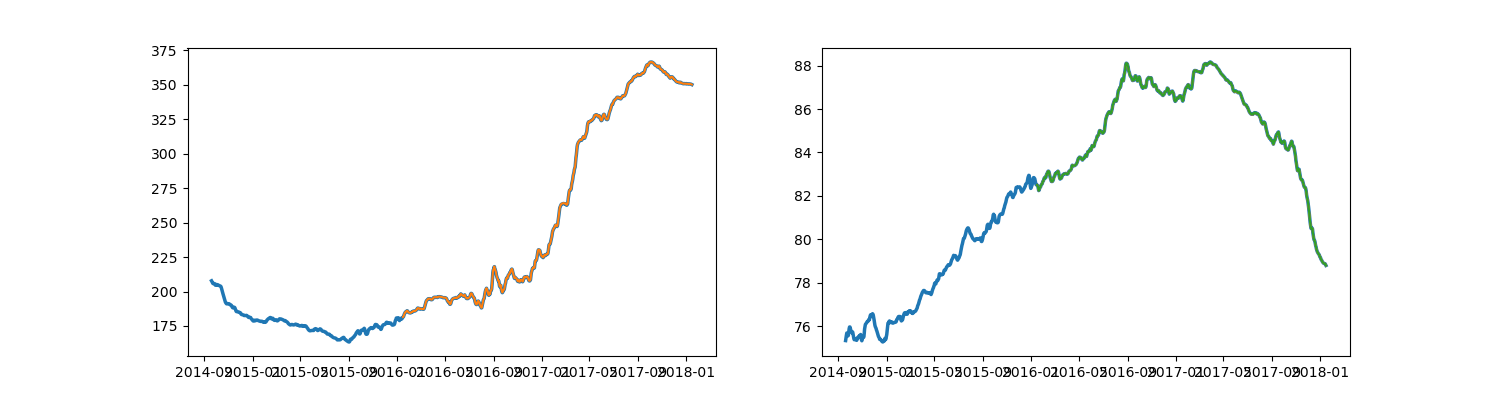

In [39]:
fig, ax = plt.subplots(1, 2, sharex = True, figsize = (15, 4))
ax[0].plot(Pdate, Plon, lw = 2.5, )
ax[0].plot(traj_sel.stamps, lon_traj+360)
ax[1].plot(Pdate, Plat, lw = 2.5, )
ax[1].plot(traj_sel.stamps, lat_traj)
ax[1].plot(traj_sel.stamps, Plat_ip)

In [17]:
from scipy.interpolate import interp1d

In [30]:
Plat_ip = interp1d(P.time_num, Plat)(date2num(traj_sel.stamps))
Plon_ip = interp1d(P.time_num, Plon)(date2num(traj_sel.stamps))

In [34]:
from kval.geo import geocalc 

In [48]:
x_km_diff = np.array([geocalc.great_circle_distance(tlon, tlat, plon, plat) for tlon, tlat, plon, plat in zip(lon_traj, lat_traj, Plon_ip, Plat_ip)])

In [52]:
x_km_total = np.array([geocalc.great_circle_distance(tlon, tlat,  lon_traj[0], lat_traj[0]) for tlon, tlat in zip(lon_traj, lat_traj,)])

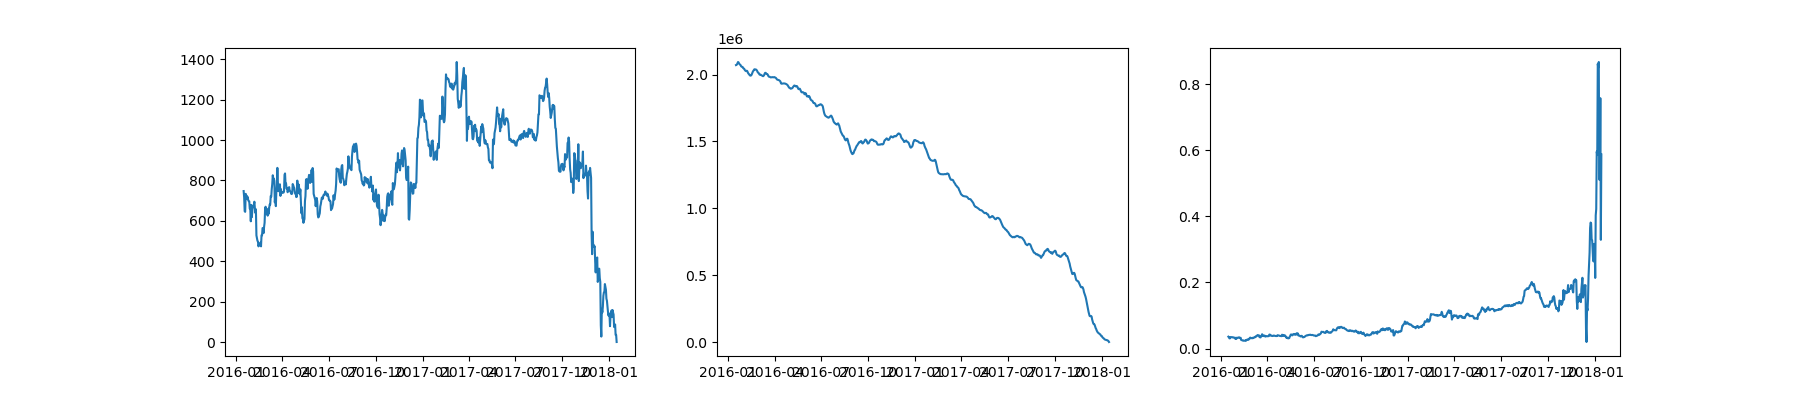

In [54]:
fig, ax = plt.subplots(1, 3, figsize = (18, 4))
ax[0].plot(traj_sel.stamps, x_km_diff)
ax[1].plot(traj_sel.stamps, x_km_total)
ax[2].plot(traj_sel.stamps, x_km_diff/x_km_total*100)